# Sprint 2: Model Building and Evaluation

## Objective
To train multiple classification algorithms using the
cleaned Bank Marketing dataset and identify the best
performing baseline model.

**Step 1 — Import Required Libraries**

In [1]:
# Importing required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Model saving
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load processed training and testing datasets

train_df = pd.read_csv("../data/processed/train_processed.csv")

test_df = pd.read_csv("../data/processed/test_processed.csv")

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (36168, 52)
Testing Dataset Shape: (9043, 52)


In [4]:
# Display training dataset

train_df.head()

,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,y
0,-0.463826,-0.062807,1.582124,-0.245119,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
1,-1.617412,2.146006,-1.298384,1.004857,1.446096,0.0,2.119745,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
2,0.305232,-0.586246,-0.458236,1.004857,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
3,0.689761,-0.793246,1.822166,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,-0.271561,-0.575217,1.222060,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


In [5]:
# Display testing dataset

test_df.head()

,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,y
0,-0.079297,-0.250295,-0.938321,-0.245119,-0.41091,0.0,-0.471755,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
1,0.305232,-0.472565,1.702145,-0.245119,-0.41091,0.0,-0.471755,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
2,-0.944487,-0.491229,0.501933,1.629845,-0.41091,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
3,-0.463826,-0.237570,0.861997,1.004857,-0.41091,0.0,-0.471755,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,-0.656090,0.836455,-1.418405,-0.870107,-0.41091,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


Understand the dataset columns

In [6]:
# Display all training dataset columns

print("Training Dataset Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 Records:")
display(train_df.head())

Training Dataset Columns:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_divorced', 'marital_married', 'marital_single', 'education_primary', 'education_secondary', 'education_tertiary', 'education_unknown', 'default_no', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'contact_unknown', 'month_apr', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown', 'y']

First 5 Records:


,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,y
0,-0.463826,-0.062807,1.582124,-0.245119,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
1,-1.617412,2.146006,-1.298384,1.004857,1.446096,0.0,2.119745,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
2,0.305232,-0.586246,-0.458236,1.004857,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
3,0.689761,-0.793246,1.822166,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,-0.271561,-0.575217,1.222060,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


In [7]:
# Check target column

print("Last 10 columns:")
print(train_df.columns[-10:].tolist())

Last 10 columns:
['month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown', 'y']


Separate X and y

In [8]:
# Separate independent and dependent variables

X_train = train_df.drop("y", axis=1)
y_train = train_df["y"]

X_test = test_df.drop("y", axis=1)
y_test = test_df["y"]

# Display shapes

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (36168, 51)
y_train Shape: (36168,)
X_test Shape: (9043, 51)
y_test Shape: (9043,)


Check target distribution

In [9]:
# Check target distribution in training data

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTraining Target Percentage:")
print(y_train.value_counts(normalize=True) * 100)


# Check target distribution in testing data

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nTesting Target Percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training Target Distribution:
y
0    31937
1     4231
Name: count, dtype: int64

Training Target Percentage:
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    7985
1    1058
Name: count, dtype: int64

Testing Target Percentage:
y
0    88.300343
1    11.699657
Name: proportion, dtype: float64


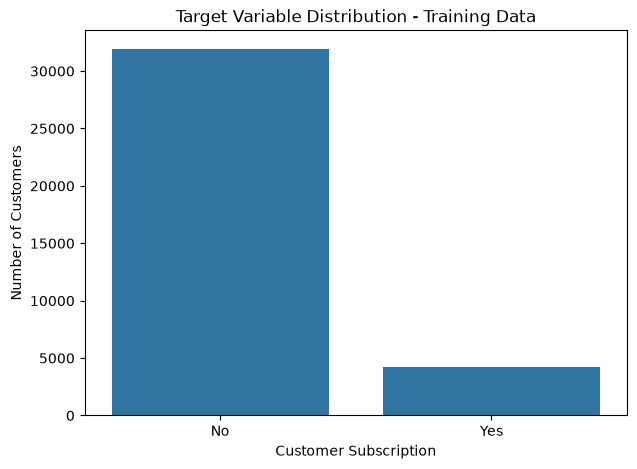

In [10]:
# Visualize target distribution

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Target Variable Distribution - Training Data")
plt.xlabel("Customer Subscription")
plt.ylabel("Number of Customers")

plt.xticks([0, 1], ["No", "Yes"])

plt.show()

**Logistic Regression – Baseline Model**

In [11]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model

lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [12]:
# Predict on training data

y_train_pred = lr_model.predict(X_train)

# Predict on testing data

y_test_pred = lr_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [13]:
# Calculate accuracy

train_accuracy = accuracy_score(y_train, y_train_pred)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8928057951780579
Testing Accuracy: 0.8929558774742895


In [14]:
# Classification Report

print("Logistic Regression - Classification Report")

print(classification_report(y_test, y_test_pred))

Logistic Regression - Classification Report
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.86      9043



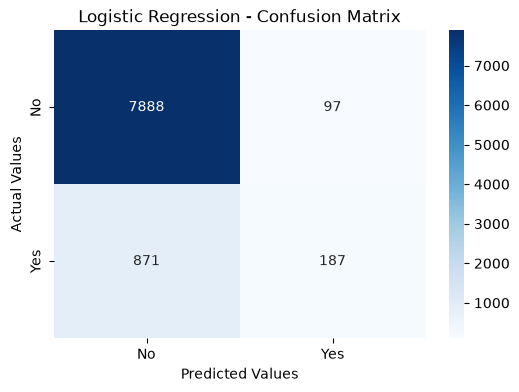

In [15]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [16]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(y_test, y_test_pred, zero_division=0)

recall = recall_score(y_test, y_test_pred, zero_division=0)

f1 = f1_score(y_test, y_test_pred, zero_division=0)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8929558774742895
Precision: 0.6584507042253521
Recall   : 0.1767485822306238
F1 Score : 0.2786885245901639


Decision Tree Classifier

In [17]:
# Import Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model

dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [18]:
# Predict on training data

dt_train_pred = dt_model.predict(X_train)

# Predict on testing data

dt_test_pred = dt_model.predict(X_test)

print("Decision Tree Predictions Completed!")

Decision Tree Predictions Completed!


In [19]:
# Calculate training and testing accuracy

dt_train_accuracy = accuracy_score(y_train, dt_train_pred)

dt_test_accuracy = accuracy_score(y_test, dt_test_pred)

print("Decision Tree Training Accuracy:", dt_train_accuracy)

print("Decision Tree Testing Accuracy:", dt_test_accuracy)

Decision Tree Training Accuracy: 1.0
Decision Tree Testing Accuracy: 0.833020015481588


In [20]:
# Decision Tree Classification Report

print("Decision Tree Classification Report")

print(classification_report(y_test, dt_test_pred))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      7985
           1       0.30      0.33      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.61      0.61      0.61      9043
weighted avg       0.84      0.83      0.84      9043



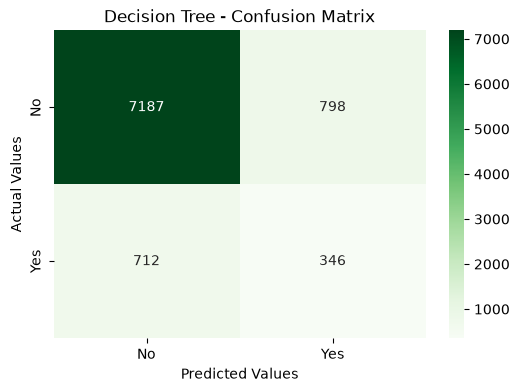

In [21]:
# Decision Tree Confusion Matrix

cm_dt = confusion_matrix(y_test, dt_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

Random Forest Classifier

In [22]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [23]:
# Predict on training data

rf_train_pred = rf_model.predict(X_train)

# Predict on testing data

rf_test_pred = rf_model.predict(X_test)

print("Random Forest Predictions Completed!")

Random Forest Predictions Completed!


In [24]:
# Calculate training and testing accuracy

rf_train_accuracy = accuracy_score(y_train, rf_train_pred)

rf_test_accuracy = accuracy_score(y_test, rf_test_pred)

print("Random Forest Training Accuracy:", rf_train_accuracy)

print("Random Forest Testing Accuracy:", rf_test_accuracy)

Random Forest Training Accuracy: 0.999944702499447
Random Forest Testing Accuracy: 0.8932876257879022


In [25]:
# Random Forest Classification Report

print("Random Forest Classification Report")

print(classification_report(y_test, rf_test_pred))

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.62      0.23      0.34      1058

    accuracy                           0.89      9043
   macro avg       0.76      0.61      0.64      9043
weighted avg       0.87      0.89      0.87      9043



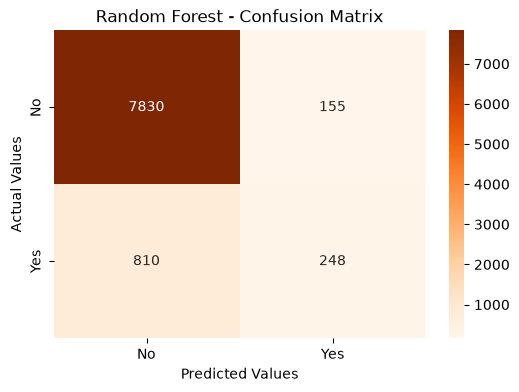

In [26]:
# Random Forest Confusion Matrix

cm_rf = confusion_matrix(y_test, rf_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Random Forest - Confusion Matrix")

plt.show()

Support Vector Machine (SVM)

In [27]:
# Import Support Vector Classifier

from sklearn.svm import SVC

# Create SVM model

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Train the model

svm_model.fit(X_train, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [28]:
# Predict on training data

svm_train_pred = svm_model.predict(X_train)

# Predict on testing data

svm_test_pred = svm_model.predict(X_test)

print("SVM Predictions Completed!")

SVM Predictions Completed!


In [29]:
# Calculate training and testing accuracy

svm_train_accuracy = accuracy_score(y_train, svm_train_pred)

svm_test_accuracy = accuracy_score(y_test, svm_test_pred)

print("SVM Training Accuracy:", svm_train_accuracy)

print("SVM Testing Accuracy:", svm_test_accuracy)

SVM Training Accuracy: 0.8958748064587481
SVM Testing Accuracy: 0.8943934534999447


In [30]:
# SVM Classification Report

print("SVM Classification Report")

print(classification_report(y_test, svm_test_pred))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.67      0.19      0.30      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.59      0.62      9043
weighted avg       0.87      0.89      0.87      9043



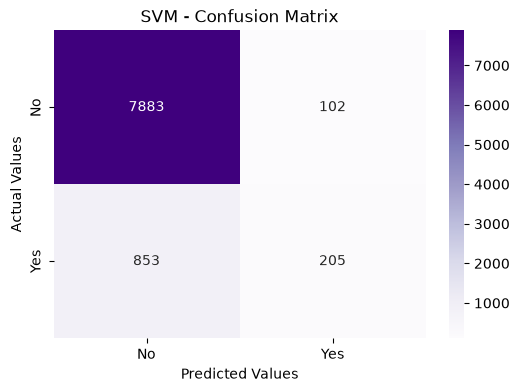

In [31]:
# SVM Confusion Matrix

cm_svm = confusion_matrix(y_test, svm_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("SVM - Confusion Matrix")

plt.show()

Gaussian Naive Bayes

In [32]:
# Import Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

# Create model

nb_model = GaussianNB()

# Train model

nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes Model Trained Successfully!")

Gaussian Naive Bayes Model Trained Successfully!


In [33]:
# Predict on training data

nb_train_pred = nb_model.predict(X_train)

# Predict on testing data

nb_test_pred = nb_model.predict(X_test)

print("Naive Bayes Predictions Completed!")

Naive Bayes Predictions Completed!


In [34]:
# Calculate accuracy

nb_train_accuracy = accuracy_score(y_train, nb_train_pred)

nb_test_accuracy = accuracy_score(y_test, nb_test_pred)

print("Naive Bayes Training Accuracy:", nb_train_accuracy)

print("Naive Bayes Testing Accuracy:", nb_test_accuracy)

Naive Bayes Training Accuracy: 0.838365405883654
Naive Bayes Testing Accuracy: 0.8426407165763574


In [35]:
# Naive Bayes Classification Report

print("Gaussian Naive Bayes Classification Report")

print(classification_report(y_test, nb_test_pred))

Gaussian Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.93      0.89      0.91      7985
           1       0.36      0.46      0.41      1058

    accuracy                           0.84      9043
   macro avg       0.64      0.68      0.66      9043
weighted avg       0.86      0.84      0.85      9043



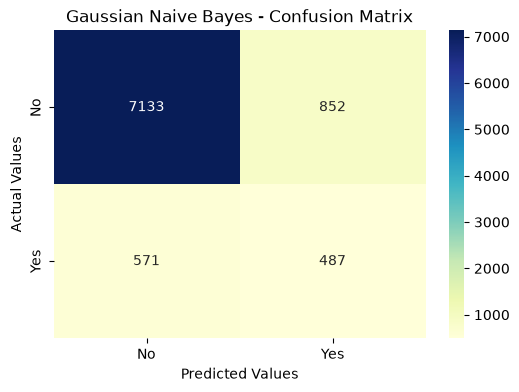

In [36]:
# Naive Bayes Confusion Matrix

cm_nb = confusion_matrix(y_test, nb_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Gaussian Naive Bayes - Confusion Matrix")

plt.show()

**Compare all five models**

In [37]:
# Create model comparison

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "Gaussian Naive Bayes"
    ],

    "Training Accuracy": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_train, dt_train_pred),
        accuracy_score(y_train, rf_train_pred),
        accuracy_score(y_train, svm_train_pred),
        accuracy_score(y_train, nb_train_pred)
    ],

    "Testing Accuracy": [
        accuracy_score(y_test, y_test_pred),
        accuracy_score(y_test, dt_test_pred),
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, svm_test_pred),
        accuracy_score(y_test, nb_test_pred)
    ],

    "Precision": [
        precision_score(y_test, y_test_pred, zero_division=0),
        precision_score(y_test, dt_test_pred, zero_division=0),
        precision_score(y_test, rf_test_pred, zero_division=0),
        precision_score(y_test, svm_test_pred, zero_division=0),
        precision_score(y_test, nb_test_pred, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, dt_test_pred, zero_division=0),
        recall_score(y_test, rf_test_pred, zero_division=0),
        recall_score(y_test, svm_test_pred, zero_division=0),
        recall_score(y_test, nb_test_pred, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, dt_test_pred, zero_division=0),
        f1_score(y_test, rf_test_pred, zero_division=0),
        f1_score(y_test, svm_test_pred, zero_division=0),
        f1_score(y_test, nb_test_pred, zero_division=0)
    ]

})

model_comparison = model_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score
0,Gaussian Naive Bayes,0.8384,0.8426,0.3637,0.4603,0.4063
1,Random Forest,0.9999,0.8933,0.6154,0.2344,0.3395
2,Decision Tree,1.0000,0.8330,0.3024,0.3270,0.3143
3,SVM,0.8959,0.8944,0.6678,0.1938,0.3004
4,Logistic Regression,0.8928,0.8930,0.6585,0.1767,0.2787


Gaussian Naive Bayes: Best recall and F1 score. It identifies more customers who subscribe to the term deposit, but also produces more false positives.



Random Forest: Good accuracy and better F1 than the other models except Naive Bayes. However, its training accuracy is almost 100%, indicating overfitting.



Decision Tree: Training accuracy is 100%, but testing accuracy is only 83.30%, showing clear overfitting.



SVM: Highest precision, but low recall. It misses many actual subscribers.



Logistic Regression: Good accuracy, but low recall for the positive class.

In [38]:
# Calculate ROC-AUC scores for all baseline models

model_scores = {
    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],
    "Decision Tree": dt_model.predict_proba(X_test)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test)[:, 1],
    "SVM": svm_model.decision_function(X_test),
    "Gaussian Naive Bayes": nb_model.predict_proba(X_test)[:, 1]
}

for name, scores in model_scores.items():
    auc = roc_auc_score(y_test, scores)
    print(f"{name}: {auc:.4f}")

Logistic Regression: 0.7750
Decision Tree: 0.6135
Random Forest: 0.7890
SVM: 0.7179
Gaussian Naive Bayes: 0.7515


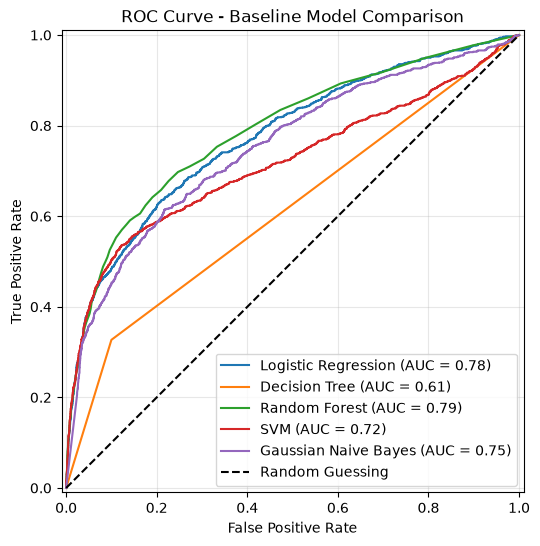

In [39]:
# Import ROC curve visualization
from sklearn.metrics import RocCurveDisplay

# Plot ROC curves
plt.figure(figsize=(9, 6))

for name, scores in model_scores.items():
    RocCurveDisplay.from_predictions(
        y_test,
        scores,
        name=name,
        ax=plt.gca()
    )

# Random guessing reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing")

plt.title("ROC Curve - Baseline Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [40]:
# Save Sprint 2 model comparison results

import os

# Create reports folder if it doesn't exist
os.makedirs("../reports", exist_ok=True)

# Save comparison table
model_comparison.to_csv(
    "../reports/sprint2_model_comparison.csv",
    index=False
)

print("Sprint 2 model comparison saved successfully!")

Sprint 2 model comparison saved successfully!


In [41]:
# Save all five baseline models

import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Store all trained models in a dictionary
baseline_models = {
    "logistic_regression": lr_model,
    "decision_tree": dt_model,
    "random_forest": rf_model,
    "svm": svm_model,
    "gaussian_naive_bayes": nb_model
}

# Save models
joblib.dump(
    baseline_models,
    "../models/sprint2_baseline_models.pkl"
)

print("All five baseline models saved successfully!")

All five baseline models saved successfully!


In [42]:
# Verify Sprint 2 output files

import os

files_to_check = [
    "../reports/sprint2_model_comparison.csv",
    "../models/sprint2_baseline_models.pkl"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"FOUND: {file}")
    else:
        print(f"MISSING: {file}")

FOUND: ../reports/sprint2_model_comparison.csv
FOUND: ../models/sprint2_baseline_models.pkl
